# Idealised lake-basin flexure: drainage-system growth and reset

**The question.** Spergel et al. observed on the Amery Ice Shelf that consecutive years of high melt produced progressively larger drainage systems. Their explanation was that water fills a depression and refreezes into an ice plug, which expands by about 9%. The next season's water cannot use that depression, so it is routed further downstream. What they did not address is how the system *resets* after 5–10 cool years.

**The hypothesis tested here.** Each season, water loads a lake basin and its floor sinks: a little at once (elastically), and the rest over a relaxation time $\tau$.

* **If $\tau$ is longer than about a year,** the basin has not finished sinking by the next season. The plug fills it, and new water is forced downstream.
* **During cool years** the floor keeps sinking, which restores the basin's capacity, and the drainage system contracts.
* **Within a season there is a race** between the lake filling and its floor sinking. Wide lakes fill slowly and relax quickly, so they tend to stay below their sills and act as terminal sinks. Narrow lakes tend to fill, overtop and extend the network. A pinned lake that keeps deepening may eventually drain by fracture instead, a possible link to the 2019 Amery lake drainage described by Warner et al. (2021).

This notebook runs the five idealised experiments of the brief with the small model in this folder ([`README.md`](README.md)):

| part | experiment | model |
|---|---|---|
| 2 | relaxation time $\tau(W, H)$ | `physics.py`: both limit formulae and the exact viscous-layer solution |
| 3 | one season: overtop or not, in $(\Pi, t_m/\tau)$ space | `basin.py`: `solve_ivp` with an event at the sill, against the analytic boundary |
| 4 | overtopping against lake width | `basin.py` with $\tau(W)$ from `physics.py` |
| 5 | one basin through 3 high and 8 cool years | `basin.py`: exact multi-year stepper with refreezing |
| 6 | a chain of basins: extent, growth and reset | `cascade.py` |

Each experiment also lives in `experiments/` as a script that writes a NetCDF file and figures to `outputs/`.

In [1]:
import os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")                     # the flexure folder: basins package and plotstyle
import plotstyle as ps
from basins import physics as ph
from basins.basin import Basin, fill_season, gap_analytic, overtop_time_analytic, critical_Pi
from basins.experiments import exp1_regime, exp2_tau_maps, exp3_width, exp4_multiyear, exp5_cascade
from basins.experiments.common import save
ps.apply()
pd.set_option("display.precision", 3)

eta_bg = ph.glen_viscosity(np.array([1e-3, 1e-2]) / ph.YEAR)
print("Glen's law (A = 1.7e-25 Pa^-3 s^-1, about -20 C) linearised about a background strain rate:")
print(f"  1e-3 per year -> eta = {eta_bg[0]:.1e} Pa s;  1e-2 per year -> eta = {eta_bg[1]:.1e} Pa s")
for H in (300, 700, 1000):
    print(f"  H = {H:4d} m: flexural length {ph.flexural_length(H, 1e9) / 1e3:.2f} km (E = 1 GPa), "
          f"{ph.flexural_length(H, 9e9) / 1e3:.2f} km (E = 9 GPa)")

Glen's law (A = 1.7e-25 Pa^-3 s^-1, about -20 C) linearised about a background strain rate:
  1e-3 per year -> eta = 9.0e+14 Pa s;  1e-2 per year -> eta = 1.9e+14 Pa s
  H =  300 m: flexural length 0.70 km (E = 1 GPa), 1.22 km (E = 9 GPa)
  H =  700 m: flexural length 1.33 km (E = 1 GPa), 2.30 km (E = 9 GPa)
  H = 1000 m: flexural length 1.74 km (E = 1 GPa), 3.01 km (E = 9 GPa)


## 1. The model

A basin is a vertical-sided box of area $A$, whose sill stands $D_0$ above the original floor. Its state is three depths:

* the water depth $h$;
* the ice-plug thickness $p$;
* the viscous part $w_v$ of the floor's deflection.

$$
L = h + \frac{\rho_i}{\rho_w}p,\qquad
w = \alpha_e L + w_v,\qquad
\frac{dw_v}{dt} = \frac{(\alpha-\alpha_e)L - w_v}{\tau},\qquad
C = D_0 + w - p - h .
$$

* $L$ is the load as a water-equivalent depth, and $w$ is the floor's deflection.
* $\alpha$ is the final deflection per metre of water-equivalent load, and $\alpha_e$ is its immediate, elastic part.
* $C$ is the free space below the sill.

**Melt season.** Inflow fills the basin until $C = 0$. The lake then sits at its sill, and whatever the deepening basin cannot take spills downstream.

**End of season.** The water refreezes: $p \leftarrow p + (\rho_w/\rho_i)h$. That leaves the load unchanged but takes 9% of the frozen depth out of $C$.

**Between seasons** the floor keeps relaxing towards $\alpha L$.

**Placeholder assumptions,** all marked in the code:

* $k = \pi/W$ or $2\pi/W$ stands in for a lake of width $W$; both are reported.
* $\alpha_e = (\rho_w/\rho_{sw})/(1+(k\ell)^4)$, the exact response of one thin-plate mode.
* The basin is a box of area $W^2$.
* All the water refreezes each winter.
* Each basin has one viscous mode.

## 2. How fast does a basin relax?  (Experiment 2)

There are two limits:

* **Thin viscous plate** (wide lakes, $kH \ll 1$): $\tau_{tp} = \eta H^3 k^4/(3\rho_{sw}g)$. Narrow lakes relax *much* more slowly, because $\tau \propto k^4$.
* **Viscous half-space** (lakes no wider than the ice is thick, $kH \gtrsim 2$): $\tau_{hs} = 2\eta k/(\rho_i g)$.

The **exact Fourier-mode solution** for a viscous layer floating on sea water joins them. Its boundary conditions are a traction-free top, gravity at both surfaces and hydrostatic sea water at the base (`physics.layer_modes`). It has two modes:

* **Fast mode.** For small $kH$ it is bending, follows $\tau_{tp}$, and sinks the floor by $\rho_w/\rho_{sw} \approx 0.97$ per metre of water.
* **Slow mode.** The ice under the lake thins by spreading, over $4\eta/(\rho_i(1-\rho_i/\rho_{sw})gH)$ (decades to centuries). It adds the last 0.12, so the final state is fully fluid, $\alpha = \rho_w/\rho_i$.

For large $kH$ a single mode with $\tau_{hs}$ and $\alpha = \rho_w/\rho_i$ carries everything.

computed in 0.3 s


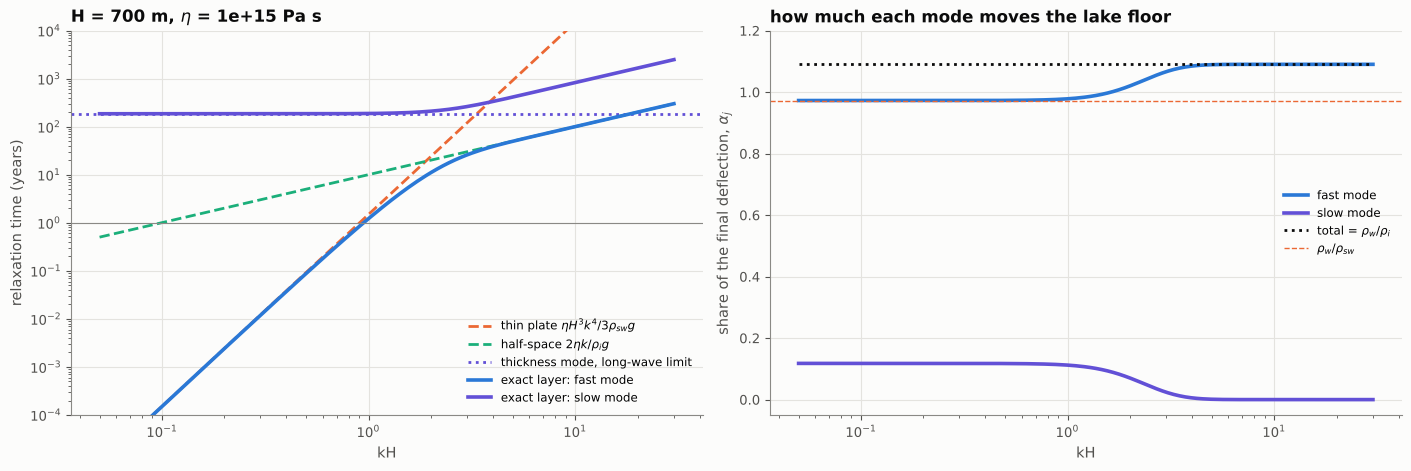

In [2]:
t0 = time.perf_counter()
ds2 = exp2_tau_maps.run()
save(ds2, "exp2_tau_maps")
print(f"computed in {time.perf_counter() - t0:.1f} s")
exp2_tau_maps.plot_curves(ds2);

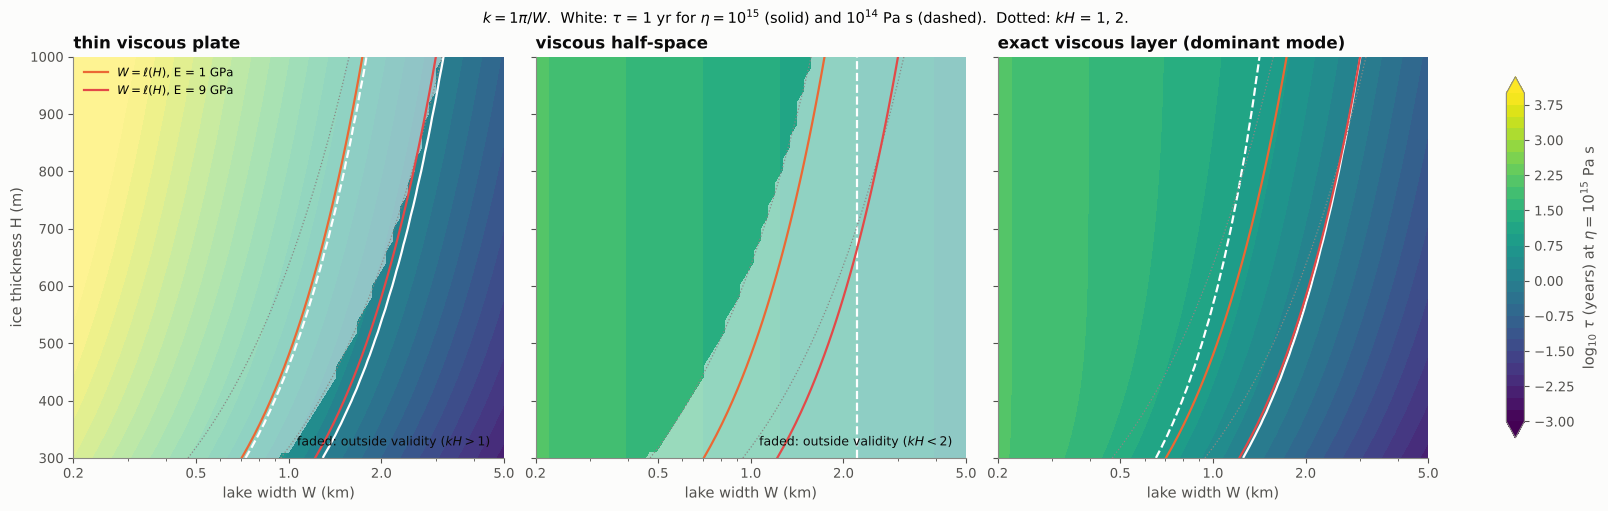

In [3]:
exp2_tau_maps.plot_maps(ds2, np.pi);

In [4]:
# width at which the exact-layer tau equals one year
rows = []
for H in (300.0, 700.0, 1000.0):
    for kf in ds2.k_factor.values:
        tau1 = ds2.tau_layer.sel(k_factor=kf).interp(H=H)            # at eta = 1e15
        for eta in (1e14, 1e15):
            t = tau1 * eta / ds2.eta
            W1 = float(np.interp(0.0, np.log(t.values[::-1]), ds2.W.values[::-1]))   # tau falls with W
            if float(t.values[-1]) > 1.0:
                W1 = np.nan                                  # tau > 1 yr even at the widest lake in the grid
            rows.append(dict(H_m=H, k=f"{kf / np.pi:g} pi/W", eta=f"{eta:.0e}", W_tau_1yr_km=W1 / 1e3))
pd.DataFrame(rows).pivot_table(index=["H_m", "k"], columns="eta", values="W_tau_1yr_km")

eta            1e+14  1e+15
H_m    k                   
300.0  1 pi/W  0.653  1.252
       2 pi/W  1.306  2.505
700.0  1 pi/W  1.143  2.326
       2 pi/W  2.285  4.652
1000.0 1 pi/W  1.416  3.010
       2 pi/W  2.831    NaN

In the table (NaN: $\tau$ exceeds a year even at 5 km), lakes **narrower** than the width shown have $\tau > 1$ year: they keep sinking for years after they fill. Lakes wider than it finish within a season. The crossover is around 1–3 km for $\eta = 10^{15}$ Pa s, and roughly half that for $10^{14}$. On the map, the fluid limit is reached through the half-space regime for narrow lakes. For wide lakes the floor first stops at the thin-plate value 0.97, and the last 0.12 needs the slow thickness mode.

## 3. One season: filling versus sinking  (Experiment 1)

Take constant inflow $Q$, no elastic part, and an empty start. The gap between the sill and the water, $g = D - h$, then has a closed form:

$$
\frac{g}{D_0} = 1 - \alpha\Pi + (\alpha-1)\Pi\frac{t}{\tau} + \alpha\Pi\,e^{-t/\tau},\qquad \Pi = \frac{\tau Q}{A D_0}.
$$

* **For $\alpha = 1$:** the lake overtops if $\Pi > 1$, at $t^* = \tau\ln[\Pi/(\Pi-1)]$.
* **For $\alpha > 1$:** the threshold rises to $\Pi_c = 1/[1-(\alpha-1)\ln(\alpha/(\alpha-1))] \approx 1.29$ for $\alpha = 1.09$.
* **For $\alpha < 1$:** the lake always overtops in the end.

The first check compares the `solve_ivp` model with this closed form.

Pi_c: alpha = 1 -> 1.000;  alpha = 1.09 -> 1.289


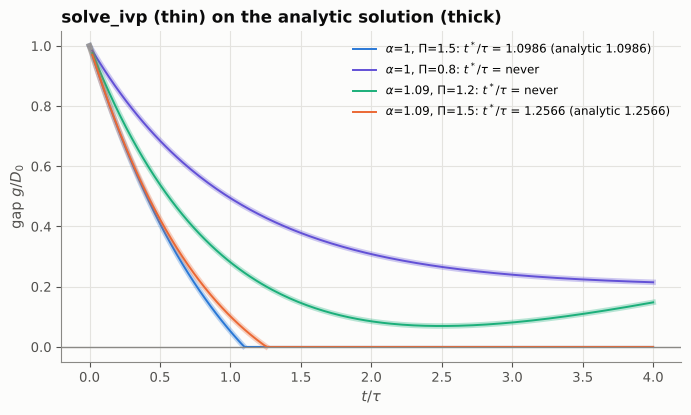

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.3))
for alpha, Pi, c in [(1.0, 1.5, ps.VISCO), (1.0, 0.8, ps.ACCENT), (1.09, 1.2, ps.ISO), (1.09, 1.5, ps.ELASTIC)]:
    b = Basin(A=1.0, D0=1.0, tau=1.0, alpha=alpha)
    r = fill_season(b, Pi, 4.0, n_out=201)
    tt = np.linspace(0, 4, 400)
    g = gap_analytic(tt, Pi, 1.0, 1.0, alpha)
    ax.plot(tt, np.where(tt <= r.attrs["t_star"], g, np.nan), color=c, lw=4, alpha=0.3)
    ax.plot(r.time, r.capacity, color=c, lw=1.4, label=rf"$\alpha$={alpha:g}, $\Pi$={Pi:g}: $t^*/\tau$ = "
            + (f"{r.attrs['t_star']:.4f} (analytic {overtop_time_analytic(Pi, 1.0, alpha):.4f})"
               if r.attrs["overtopped"] else "never"))
ax.axhline(0, color=ps.MUTED, lw=1)
ax.set(xlabel=r"$t/\tau$", ylabel=r"gap $g/D_0$", title="solve_ivp (thin) on the analytic solution (thick)")
ax.legend(fontsize=8.5);
print(f"Pi_c: alpha = 1 -> {critical_Pi(1.0):.3f};  alpha = 1.09 -> {critical_Pi(1.09):.3f}")

The regime diagram below classifies more than 6,000 one-season runs as overtopping (orange) or pinned (blue), for three values of $\alpha$, and overlays the analytic boundary. When $\tau \gg t_m$ the floor barely moves within a season, and the rigid condition $Q t_m/A > D_0$ (dotted) applies. When $\tau \lesssim t_m$ the race matters:

* with $\alpha \ge 1$ a lake below $\Pi_c$ is pinned however long the season;
* with $\alpha = 0.97$, water eventually outruns the sinking floor.

6027 runs in 9 s; agreement with the analytic boundary: {np.float64(0.973): np.float64(100.0), np.float64(1.0): np.float64(100.0), np.float64(1.091): np.float64(100.0)} %


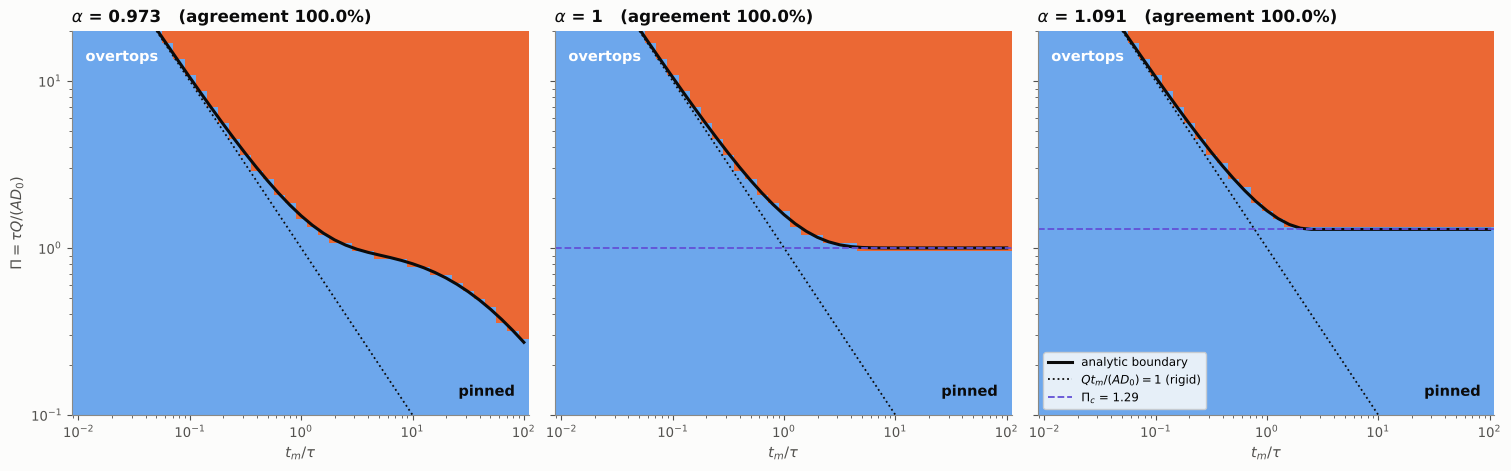

In [6]:
t0 = time.perf_counter()
ds1 = exp1_regime.run()
save(ds1, "exp1_regime")
print(f"{ds1.overtopped.size} runs in {time.perf_counter() - t0:.0f} s; agreement with the analytic boundary:",
      dict(zip(ds1.alpha.values, (100 * ds1.agreement.values).round(1))), "%")
exp1_regime.plot(ds1);

## 4. Which lakes overtop?  (Experiment 3)

Each lake now gets $(\alpha_e, \alpha, \tau)$ from its width, using the exact layer and $H$ = 700 m. The melt season is 45 days and the sill height is 2 m.

**Fixed catchment melt.** The same volume reaches every lake, so wide lakes get shallower fill depths. The rigid answer is that every lake narrower than $\sqrt{V/D_0}$ overtops. Flexure changes that only where $\tau$ is shorter than the season, which means wide lakes in warm, soft ice.

In [7]:
t0 = time.perf_counter()
ds3 = exp3_width.run()
save(ds3, "exp3_width")
print(f"computed in {time.perf_counter() - t0:.0f} s")
sw = pd.DataFrame({f"eta={eta:.0e}, k={kf / np.pi:g} pi/W": (ds3.W_switch.sel(eta=eta, k_factor=kf) / 1e3).values
                   for eta in ds3.eta.values for kf in ds3.k_factor.values},
                  index=pd.Index(ds3.V.values / 1e6, name="V (Mm3 per season)"))
sw["rigid"] = (ds3.W_switch_rigid / 1e3).values
print("widest lake that overtops (km):")
sw.round(2)

computed in 8 s
widest lake that overtops (km):


,"eta=1e+14, k=1 pi/W","eta=1e+14, k=2 pi/W","eta=1e+15, k=1 pi/W","eta=1e+15, k=2 pi/W",rigid
V (Mm3 per season),,,,,
6.0,1.51,1.68,1.68,1.68,1.73
25.0,2.46,3.06,2.90,3.41,3.54


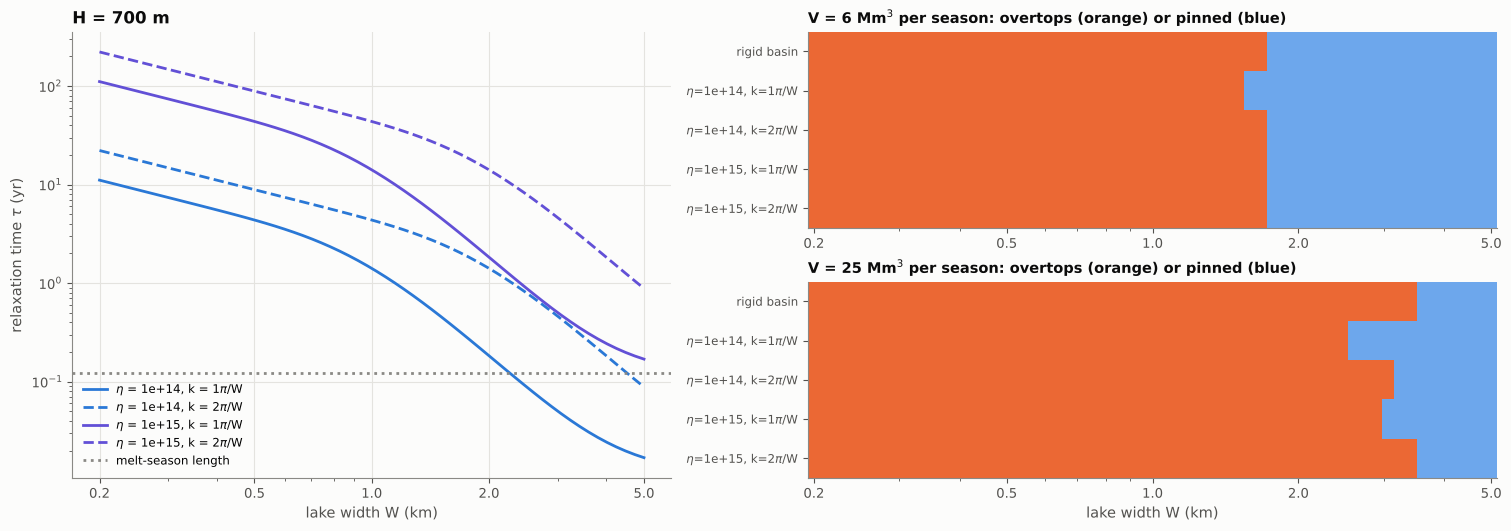

In [8]:
exp3_width.plot_fixed(ds3);

**Inflow proportional to catchment area.** If each lake's inflow scales with its own catchment, the fill depth (catchment ratio × 0.1 m of melt) is the same for every width. Only $\tau(W)$ then decides. Narrow lakes behave rigidly, overtopping once the fill depth exceeds $D_0$. Wide lakes need several times more water: their floors sink as fast as they fill, so they become **terminal sinks**.

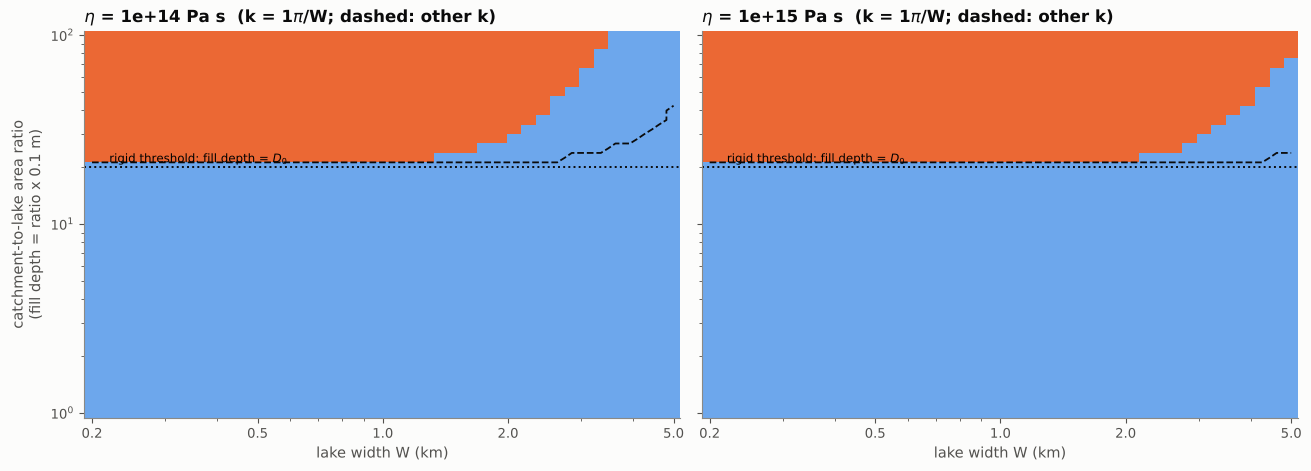

In [9]:
exp3_width.plot_ratio(ds3);

## 5. One basin through high and cool years  (Experiment 4)

There are three high years, each delivering 3 m of fill depth, then eight cool years at 10% of that, repeated. The ice is 700 m thick with $\eta = 10^{15}$ Pa s. The **narrow** basin (0.5 km) relaxes over decades; the **wide** one (3 km) within a season. The grey bands are the high years.

W = 0.5 km (tau = 44 yr): fraction of each year's inflow spilled [0.33 1.   1.   1.   0.97 0.85 0.86 0.86 0.86 0.86 0.86 0.99 0.99 0.99
 0.86 0.86 0.86 0.86 0.86 0.86 0.86 0.86]
W = 3 km (tau = 0.5 yr): fraction of each year's inflow spilled [0.05 0.31 0.41 0.   0.   0.   0.   0.   0.   0.   0.   0.54 0.67 0.71
 0.   0.   0.   0.   0.   0.   0.   0.  ]


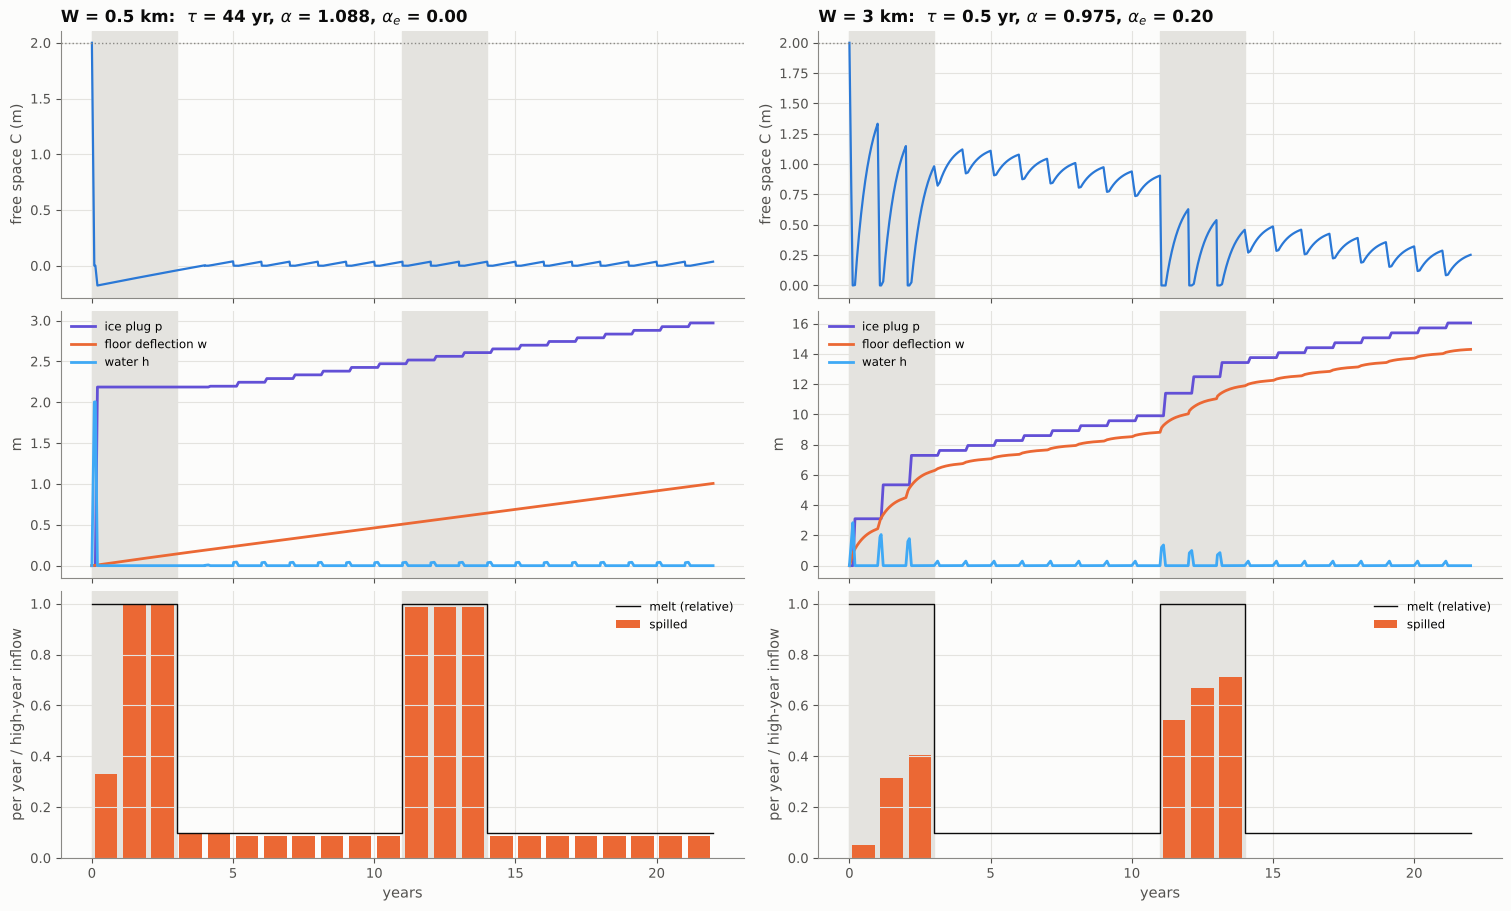

In [10]:
ds4 = exp4_multiyear.run()
save(ds4, "exp4_multiyear")
exp4_multiyear.plot_basins(ds4);
for W in ds4.width.values:
    d = ds4.sel(width=W)
    print(f"W = {W / 1e3:g} km (tau = {float(d.phys_tau_yr):.2g} yr): fraction of each year's inflow spilled",
          (d.phys_spill / d.phys_inflow).values.round(2))

**The ratchet.** Once fully relaxed, the free space is $C = D_0 - (\rho_w/\rho_i - \alpha)M$, where $M$ is the water-equivalent depth retained so far.

* With the thin-plate $\alpha = \rho_w/\rho_{sw}$, every cycle leaves the basin about $0.12M$ shallower: a slow net filling. (The slow thickness mode of §2 would remove this over decades to centuries; the single-mode basin leaves it out.)
* With the half-space $\alpha = \rho_w/\rho_i$, the plug ends up exactly flush with the original floor and the basin resets completely.

The idealised basin below relaxes in 0.3 years and gets no melt in the cool years.

alpha = 0.973: free space at the start of cycle 2 = 1.245 m (analytic 1.245 m; D0 = 2.0 m)
alpha = 1.000: free space at the start of cycle 2 = 1.397 m (analytic 1.397 m; D0 = 2.0 m)
alpha = 1.091: free space at the start of cycle 2 = 2.000 m (analytic 2.000 m; D0 = 2.0 m)


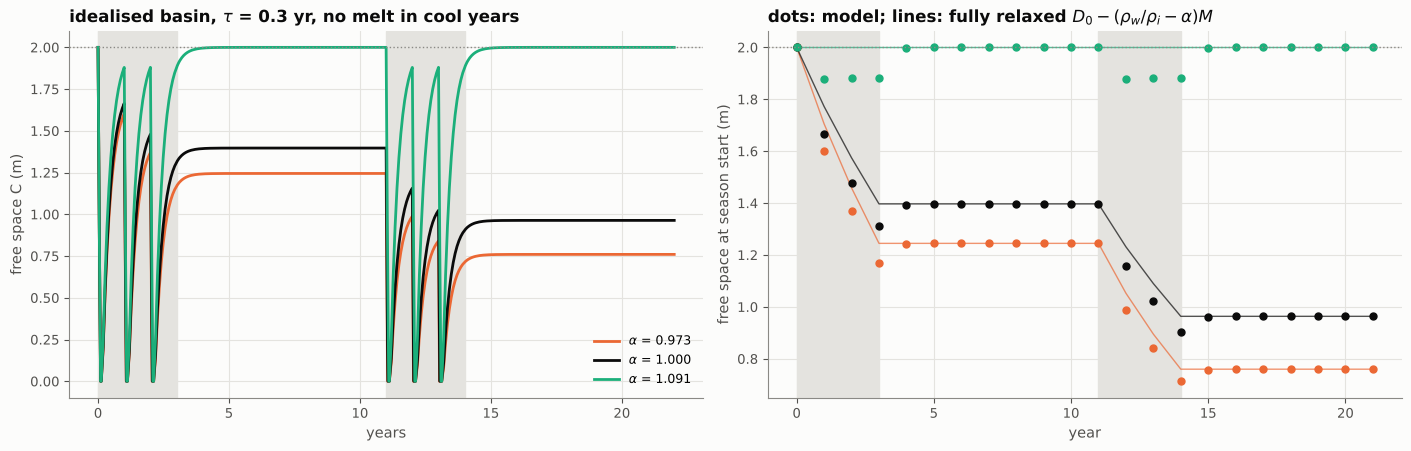

In [11]:
exp4_multiyear.plot_ratchet(ds4);
s = ds4.cycle_start.values[1:]
for al in ds4.alpha.values:
    d = ds4.sel(alpha=al)
    print(f"alpha = {al:.3f}: free space at the start of cycle 2 = {float(d.ratchet_C_start[s[0]]):.3f} m "
          f"(analytic {float(d.ratchet_C_relaxed_analytic[s[0]]):.3f} m; D0 = {ds4.D0} m)")

## 6. A chain of basins  (Experiment 5)

The chain has 15 basins along a flow line, with log-normal widths (median 1 km) and sill heights between 1 and 4 m. The ice is 700 m thick with $\eta = 3\times10^{14}$ Pa s. Each basin's spill flows into the next, and the catchment's melt enters at the head. In a high year that melt would just fill the first five empty basins.

**Extent** is the furthest basin that receives water in a year. It runs from 0 (only the head basin) to 15 (the chain overflowed). Three forcings with the same mean melt are compared:

* **cycles:** 3 high years then 8 cool years, repeated;
* **constant:** the same melt every year;
* **stochastic:** random melt each year.

computed in 12 s
extent each year (cycles): [ 4  8 11  1  1  1  1  1  1  1  1  7 11 15  2  2  2  2  2  2  2  2  9 15
 15  4  4  4  4  4  4  4  4]


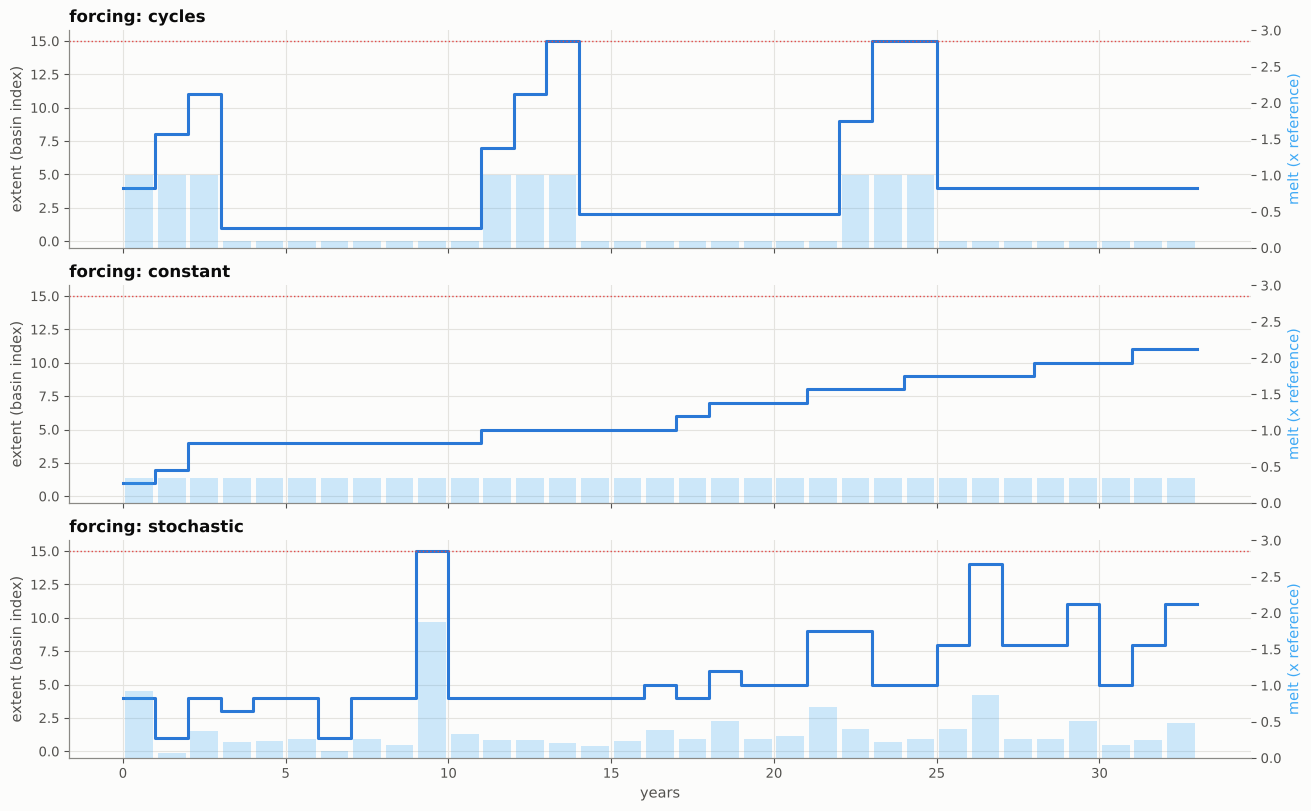

In [12]:
t0 = time.perf_counter()
ds5 = exp5_cascade.run()
save(ds5, "exp5_cascade")
print(f"computed in {time.perf_counter() - t0:.0f} s")
print("extent each year (cycles):", ds5.extent.sel(forcing="cycles").values)
exp5_cascade.plot_extent(ds5);

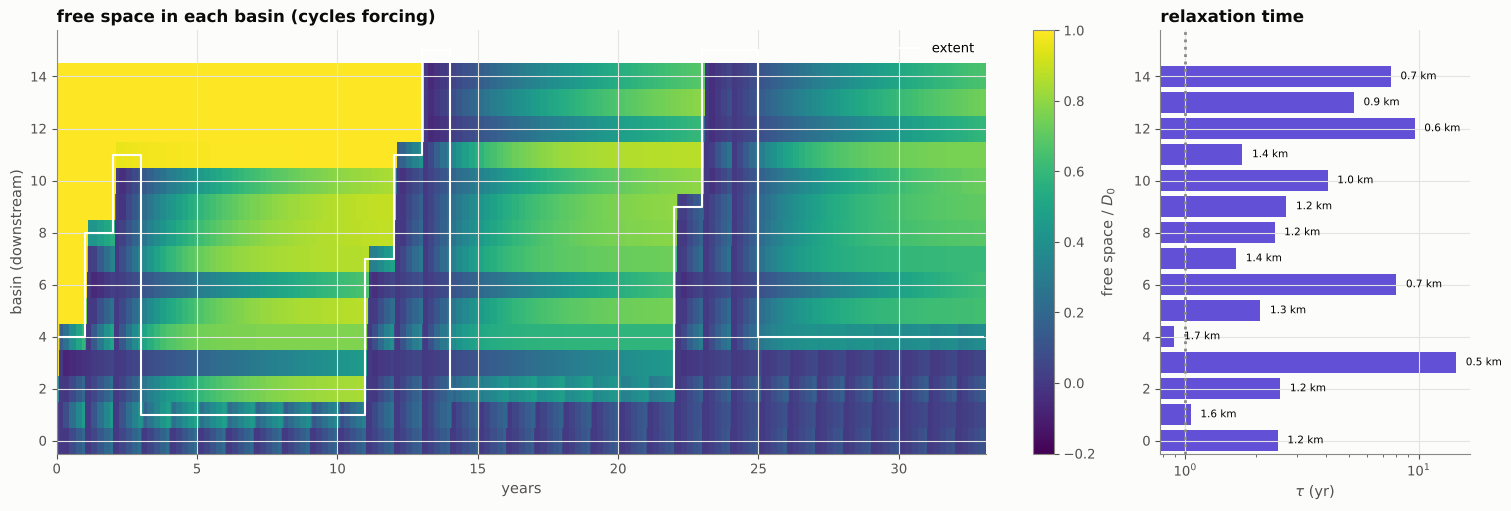

In [13]:
exp5_cascade.plot_capacity(ds5);

**Growth, memory and reset.** The left panel changes one thing at a time from the baseline: $\eta$, $H$ or the width distribution.

* *Growth* is how much further the third high year reaches than the first.
* *Memory* is how much further the first high year of the next cycle reaches than the first cycle's did; 0 means a full reset.

The right panel puts $n$ cool years between two high spells, and asks how much further the next high year reaches than a fresh system's first high year. It is run with no melt at all in the cool years (dashed: pure relaxation) and with 10% (solid).

,sens_tau_median_yr,sens_growth,sens_memory,sens_max_extent
case,,,,
eta=1e+14,0.849,1,1,9
eta=3e+14,2.546,7,3,15
eta=1e+15,8.488,11,11,15
H=300,0.366,0,1,7
H=700,2.546,7,3,15
H=1000,4.181,11,4,15
median=500,10.297,11,11,15
median=1000,2.546,7,3,15
median=2000,0.287,2,2,5


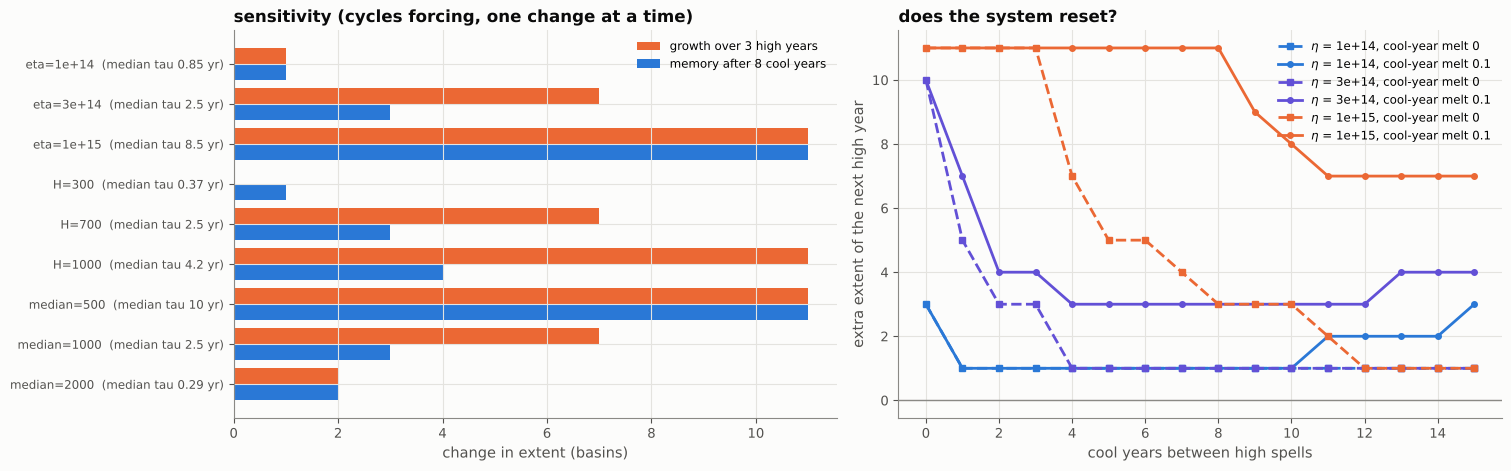

In [14]:
exp5_cascade.plot_sensitivity(ds5);
ds5[["sens_tau_median_yr", "sens_growth", "sens_memory", "sens_max_extent"]].to_dataframe()

## 7. What the experiments say

**The hypothesis holds in this idealised model.** Viscous flexure with relaxation times of a year or more produces drainage systems that grow over consecutive high-melt years and reset only slowly and incompletely. The reset time is set by the relaxation time of the slowest (narrowest) basins.

1. **The relaxation time spans orders of magnitude.** For 700 m ice, lakes narrower than about 1.1–2.3 km ($k = \pi/W$; $\eta = 10^{14}$–$10^{15}$ Pa s) need more than a year to relax, and narrow lakes in the half-space regime need decades. Wide lakes finish within a season. Because $\tau \propto \eta$, ice temperature, through the background strain rate and the rate factor $A$, matters as much as lake width. Taking $k = 2\pi/W$ instead doubles those widths.
2. **One season.** Whether a lake overtops follows the analytic boundary in $(\Pi, t_m/\tau)$ exactly (100% agreement in 6,027 runs; $\Pi_c$ = 1.29 for $\alpha$ = 1.09). If $\tau \gg t_m$ the basin behaves rigidly: it overtops once the fill depth exceeds $D_0$. Flexure matters within a season only where $\tau \lesssim t_m$, which means wide lakes in soft ice.
   * With 25 Mm³ per season, lakes 2.5–3.5 km wide that would overtop on a rigid shelf stay pinned ($\eta = 10^{14}$ Pa s, $k = \pi/W$).
   * With inflow proportional to catchment area, wide lakes need several times more water to overtop (more than five times for the widest lakes in soft ice). They act as terminal sinks.
3. **Many years in one basin.**
   * The narrow basin ($\tau$ = 44 yr) never recovers. Once its plug fills it, after a single high year, 85–100% of all later inflow passes downstream, even in cool years.
   * The wide basin ($\tau$ = 0.5 yr) recovers between seasons. It spills 5%, 31% and 41% of the inflow in successive high years and nothing in cool years. But each cycle leaves it shallower, and in the next high spell it spills 54–71%.
4. **The ratchet.** Fully relaxed, the free space follows $D_0 - (\rho_w/\rho_i - \alpha)M$ exactly. After one cycle it is 1.245 m with the thin-plate $\alpha$, 1.397 m with $\alpha$ = 1, and the full 2.000 m with the half-space $\alpha$. Narrow basins (half-space regime) can reset completely; wide ones (thin-plate regime) cannot, unless the slow thickness mode, with its decades-to-centuries time, gets to act.
5. **A chain of basins.** The extent grows through each high spell: 4, 8, then 11 basins. It shrinks in the cool years, but the next cycle starts further out (7) and overflows the chain (15).
   * Growth and memory both rise steeply with the median relaxation time. Growth over the high spell is +1 basin and memory +1 at a median of 0.85 yr ($\eta = 10^{14}$); both are +11 at 8.5 yr ($10^{15}$), or with narrow basins.
   * Thinner ice or wider basins shorten $\tau$ and suppress growth. With wide basins the extent never passes 5: they are terminal sinks.
6. **Reset.** With no melt at all in the cool years, the extra reach of the next high year decays to a single basin, which is the ratchet's residue. That takes about 1, 4 and 12 cool years for $\eta = 10^{14}$, $3\times10^{14}$ and $10^{15}$ Pa s, comparable to the 5–10-year cool spells in question. With even 10% melt in the cool years, the system does not reset: plugs keep accumulating in the head basins. Constant moderate melt makes the network creep steadily outwards, from 1 to 11 basins over 33 years.

**Caveats.** These are idealised experiments. The placeholder assumptions are listed in §1 and in [`README.md`](README.md), together with the candidate extensions:

* plug advection with ice flow;
* snow drift filling depressions;
* buried liquid lakes;
* channel incision of sills;
* a nonlinear (n = 3) load response;
* a hydrofracture threshold;
* the slow thickness mode as a second viscous element.

The NetCDF files for all five experiments are in `outputs/` (git-ignored); the scripts in `experiments/` regenerate them.